# The Problem with Linear Networks for Images

## Overview
This notebook demonstrates why traditional fully connected (linear) neural networks are problematic for image processing tasks. We'll explore the parameter explosion problem and its consequences.

## Learning Objectives
- Understand the dimensionality challenge of images
- Calculate parameter counts for fully connected layers
- Observe the computational and memory issues

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## Concept: Image Dimensionality Problem

Images are high-dimensional data. Even a modest-sized image has thousands of pixels, and each pixel can have multiple color channels.

### Example Calculation:
- Image size: 244 × 244 × 3 (RGB)
- Total input features: 244 × 244 × 3 = 178,608
- If we use a fully connected layer with 1000 neurons:
- Parameters needed: 178,608 × 1000 = 178,608,000 parameters!

In [2]:
# Calculate parameters for different image sizes
def calculate_fc_parameters(height, width, channels, hidden_units):
    input_size = height * width * channels
    parameters = input_size * hidden_units + hidden_units  # weights + biases
    return input_size, parameters

# Different image sizes
image_sizes = [
    (28, 28, 1, "MNIST"),
    (32, 32, 3, "CIFAR-10"),
    (224, 224, 3, "ImageNet"),
    (244, 244, 3, "Our Example")
]

hidden_units = 1000

print(f"Parameter count for FC layer with {hidden_units} hidden units:")
print("-" * 60)
for h, w, c, name in image_sizes:
    input_size, params = calculate_fc_parameters(h, w, c, hidden_units)
    print(f"{name:12} ({h}×{w}×{c}): {input_size:8,} inputs → {params:12,} parameters")
    print(f"             Memory: ~{params * 4 / 1024 / 1024:.1f} MB (float32)")
    print()

Parameter count for FC layer with 1000 hidden units:
------------------------------------------------------------
MNIST        (28×28×1):      784 inputs →      785,000 parameters
             Memory: ~3.0 MB (float32)

CIFAR-10     (32×32×3):    3,072 inputs →    3,073,000 parameters
             Memory: ~11.7 MB (float32)

ImageNet     (224×224×3):  150,528 inputs →  150,529,000 parameters
             Memory: ~574.2 MB (float32)

Our Example  (244×244×3):  178,608 inputs →  178,609,000 parameters
             Memory: ~681.3 MB (float32)



## Code Example: Creating a Fully Connected Network for Images

In [11]:
class LinearImageClassifierSimple(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(input_size, hidden_size)

    def forward(self, x):
        x = self.flatten(x)
        return self.fc(x)

# Create models for different image sizes
models = {}

for h, w, c, name in image_sizes:
    input_size = h * w * c
    model = LinearImageClassifierSimple(input_size, 1000)
    models[name] = model

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    print(f"{name}: {total_params:,} total parameters")

MNIST: 785,000 total parameters
CIFAR-10: 3,073,000 total parameters
ImageNet: 150,529,000 total parameters
Our Example: 178,609,000 total parameters


## Visualizing the Parameter Explosion

### Memory Calculations

The Formula: parameters × 4 ÷ 1024 ÷ 1024, if paramaters is `150,529,000`
1. `p * 4`: Convert parameters to bytes
    - Each parameter is stored as float32 (32-bit floating point)
    - float32 = 4 bytes per parameter
    - So: 150,529,000 parameters × 4 bytes = 602,116,000 bytes
2. `÷ 1024`: Convert bytes to kilobytes (KB)
    - 602,116,000 bytes ÷ 1024 = 587,613.3 KB
3. `÷ 1024`: Convert KB to megabytes (MB)
    - 587,613.3 KB ÷ 1024 = 573.8 MB

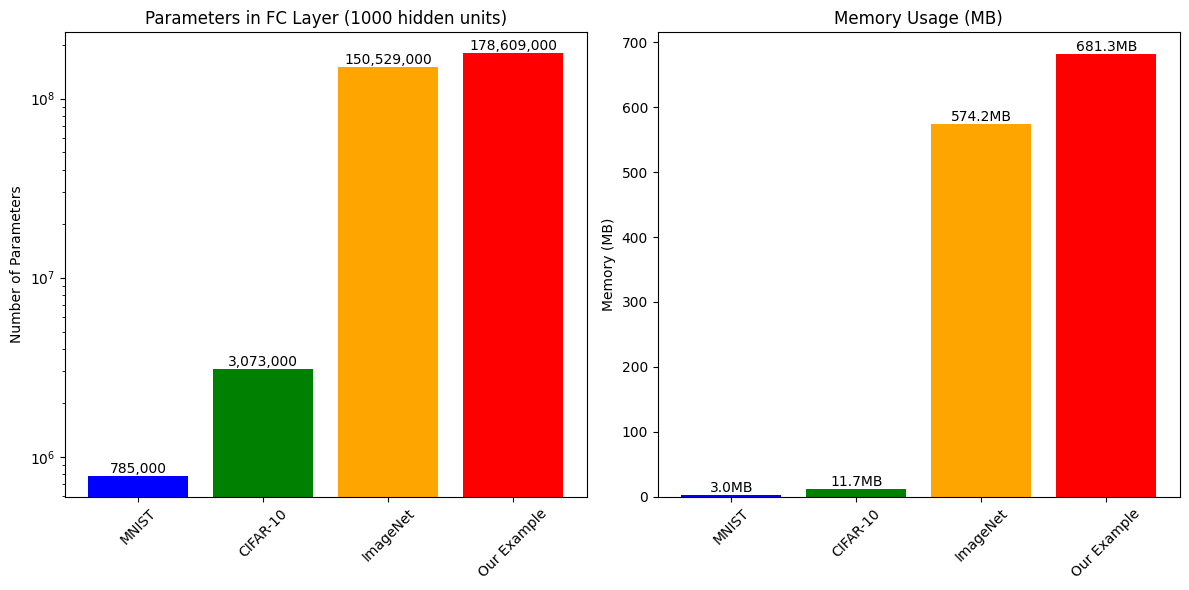

In [12]:
# Create visualization of parameter growth
image_pixels = [h*w*c for h, w, c, _ in image_sizes]
param_counts = [calculate_fc_parameters(h, w, c, 1000)[1] for h, w, c, _ in image_sizes]
names = [name for _, _, _, name in image_sizes]

plt.figure(figsize=(12, 6))

# Plot 1: Input size vs Parameters
plt.subplot(1, 2, 1)
plt.bar(names, param_counts, color=['blue', 'green', 'orange', 'red'])
plt.title('Parameters in FC Layer (1000 hidden units)')
plt.ylabel('Number of Parameters')
plt.xticks(rotation=45)
plt.yscale('log')

# Add value labels
for i, v in enumerate(param_counts):
    plt.text(i, v, f'{v:,.0f}', ha='center', va='bottom')

# Plot 2: Memory usage
plt.subplot(1, 2, 2)
memory_mb = [p * 4 / 1024 / 1024 for p in param_counts]  # float32 = 4 bytes
plt.bar(names, memory_mb, color=['blue', 'green', 'orange', 'red'])
plt.title('Memory Usage (MB)')
plt.ylabel('Memory (MB)')
plt.xticks(rotation=45)

# Add value labels
for i, v in enumerate(memory_mb):
    plt.text(i, v, f'{v:.1f}MB', ha='center', va='bottom')

plt.tight_layout()
plt.show()

## Key Problems Demonstrated

### 1. **Parameter Explosion**
- Linear growth in image size leads to quadratic growth in parameters
- ImageNet-sized images require millions of parameters for just one layer

### 2. **Memory Issues**
- Large parameter count requires significant GPU/RAM memory
- Training becomes computationally expensive

### 3. **Overfitting Risk**
- Too many parameters relative to training data
- Model memorizes rather than generalizes

### 4. **Ignores Spatial Structure**
- Treats each pixel independently
- Loses spatial relationships between neighboring pixels

## Conclusion

Fully connected networks are fundamentally unsuitable for image processing due to:
- Excessive parameter counts
- High computational costs
- Inability to leverage spatial structure

**Solution**: We need a new approach that respects the spatial nature of images → **Convolutional Neural Networks**